# Assignment No. 4 — Data Preprocessing Using NumPy, Pandas & Seaborn

**Dataset:** 20 students (Student Name, Age, Gender, Study Hours, Attendance, Marks)

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

## Task: Create the dataset (20 students)

The raw dataset intentionally contains **2 missing values** and **1 duplicate record**, so the missing-value and duplicate questions can be demonstrated. The data is saved as `students_raw.csv`.

In [2]:
data = {
    "Student Name": [
        "Ali Khan", "Ayesha Malik", "Bilal Ahmed", "Fatima Noor", "Hamza Sheikh",
        "Hira Aslam", "Imran Qureshi", "Javeria Tariq", "Kamran Raza", "Laiba Siddiqui",
        "Muneeb Iqbal", "Nimra Farooq", "Omar Hassan", "Pari Zahid", "Qasim Ali",
        "Rabia Anwar", "Saad Mehmood", "Tooba Shah", "Usman Ghani", "Zainab Butt"
    ],
    "Age":        [20, 21, 22, 20, 23, 21, 22, 20, 24, 21, 22, 20, 23, 21, 22, 20, 23, 21, 22, 20],
    "Gender":     ["Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female",
                   "Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female"],
    "Study Hours":[6.5, 8.0, 4.0, 9.0, 5.5, 7.5, 3.0, 8.5, 2.5, 7.0, 5.0, 9.5, 6.0, 4.5, 3.5, 8.0, 5.0, 6.5, 7.0, 9.0],
    "Attendance": [88, 95, 72, 98, 80, 91, 65, 96, 60, 90, 78, 99, 85, 74, 68, 94, 79, 87, 92, 97],
    "Marks":      [72, 85, 55, 91, 64, 78, 45, 88, 40, 76, 60, 94, 70, 58, 50, 84, 62, 73, 80, 90],
}
df_clean = pd.DataFrame(data)

# Introduce 2 missing values and 1 duplicate record (for the preprocessing questions)
df_raw = df_clean.copy()
df_raw.loc[4, "Study Hours"] = np.nan      # Hamza Sheikh - missing study hours
df_raw.loc[13, "Attendance"] = np.nan      # Pari Zahid - missing attendance
df_raw = pd.concat([df_raw, df_raw.iloc[[2]]], ignore_index=True)   # duplicate of Bilal Ahmed

df_raw.to_csv("students_raw.csv", index=False)
print("Raw dataset saved. Shape:", df_raw.shape)

Raw dataset saved. Shape: (21, 6)


## Question 1: NumPy array of marks — mean, median, standard deviation

In [3]:
marks_array = np.array(df_clean["Marks"])
print("Marks array:", marks_array)

mean_marks   = np.mean(marks_array)
median_marks = np.median(marks_array)
std_marks    = np.std(marks_array)

print(f"Mean               : {mean_marks:.2f}")
print(f"Median             : {median_marks:.2f}")
print(f"Standard Deviation : {std_marks:.2f}")

Marks array: [72 85 55 91 64 78 45 88 40 76 60 94 70 58 50 84 62 73 80 90]
Mean               : 70.75
Median             : 72.50
Standard Deviation : 15.58


## Question 2: Create a Pandas DataFrame using the dataset

In [4]:
df = pd.read_csv("students_raw.csv")
print("Shape:", df.shape)
df

Shape: (21, 6)


,Student Name,Age,Gender,Study Hours,Attendance,Marks
0,Ali Khan,20,Male,6.5,88.0,72
1,Ayesha Malik,21,Female,8.0,95.0,85
2,Bilal Ahmed,22,Male,4.0,72.0,55
3,Fatima Noor,20,Female,9.0,98.0,91
4,Hamza Sheikh,23,Male,NaN,80.0,64
5,Hira Aslam,21,Female,7.5,91.0,78
6,Imran Qureshi,22,Male,3.0,65.0,45
7,Javeria Tariq,20,Female,8.5,96.0,88
8,Kamran Raza,24,Male,2.5,60.0,40
9,Laiba Siddiqui,21,Female,7.0,90.0,76


In [5]:
df.info()
print()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Student Name  21 non-null     str    
 1   Age           21 non-null     int64  
 2   Gender        21 non-null     str    
 3   Study Hours   20 non-null     float64
 4   Attendance    20 non-null     float64
 5   Marks         21 non-null     int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 1.1 KB



,Age,Study Hours,Attendance,Marks
count,21.000000,20.000000,20.000000,21.000000
mean,21.428571,6.200000,84.300000,70.000000
std,1.207122,2.154555,11.890288,15.959323
min,20.000000,2.500000,60.000000,40.000000
25%,20.000000,4.375000,76.500000,58.000000
50%,21.000000,6.500000,87.500000,72.000000
75%,22.000000,8.000000,94.250000,84.000000
max,24.000000,9.500000,99.000000,94.000000


## Question 3: Identify and handle missing values

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Rows with missing values:")
df[df.isnull().any(axis=1)]

Missing values per column:
Student Name    0
Age             0
Gender          0
Study Hours     1
Attendance      1
Marks           0
dtype: int64

Rows with missing values:


,Student Name,Age,Gender,Study Hours,Attendance,Marks
4,Hamza Sheikh,23,Male,NaN,80.0,64
13,Pari Zahid,21,Female,4.5,NaN,58


In [7]:
# Handling: fill numeric columns with the column median
df["Study Hours"] = df["Study Hours"].fillna(df["Study Hours"].median())
df["Attendance"]  = df["Attendance"].fillna(df["Attendance"].median())

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Student Name    0
Age             0
Gender          0
Study Hours     0
Attendance      0
Marks           0
dtype: int64


## Question 4: Find duplicate records and remove them

In [8]:
print("Number of duplicate rows:", df.duplicated().sum())
print()
print("Duplicate records:")
print(df[df.duplicated(keep=False)])

Number of duplicate rows: 1

Duplicate records:
   Student Name  Age Gender  Study Hours  Attendance  Marks
2   Bilal Ahmed   22   Male          4.0        72.0     55
20  Bilal Ahmed   22   Male          4.0        72.0     55


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

df.to_csv("students_cleaned.csv", index=False)
df

Shape after removing duplicates: (20, 6)
Duplicates remaining: 0


,Student Name,Age,Gender,Study Hours,Attendance,Marks
0,Ali Khan,20,Male,6.5,88.0,72
1,Ayesha Malik,21,Female,8.0,95.0,85
2,Bilal Ahmed,22,Male,4.0,72.0,55
3,Fatima Noor,20,Female,9.0,98.0,91
4,Hamza Sheikh,23,Male,6.5,80.0,64
5,Hira Aslam,21,Female,7.5,91.0,78
6,Imran Qureshi,22,Male,3.0,65.0,45
7,Javeria Tariq,20,Female,8.5,96.0,88
8,Kamran Raza,24,Male,2.5,60.0,40
9,Laiba Siddiqui,21,Female,7.0,90.0,76


## Question 5: Filter students who scored more than 70 marks

In [10]:
top_students = df[df["Marks"] > 70]
print("Students with Marks > 70:", len(top_students))
top_students

Students with Marks > 70: 11


,Student Name,Age,Gender,Study Hours,Attendance,Marks
0,Ali Khan,20,Male,6.5,88.0,72
1,Ayesha Malik,21,Female,8.0,95.0,85
3,Fatima Noor,20,Female,9.0,98.0,91
5,Hira Aslam,21,Female,7.5,91.0,78
7,Javeria Tariq,20,Female,8.5,96.0,88
9,Laiba Siddiqui,21,Female,7.0,90.0,76
11,Nimra Farooq,20,Female,9.5,99.0,94
15,Rabia Anwar,20,Female,8.0,94.0,84
17,Tooba Shah,21,Female,6.5,87.0,73
18,Usman Ghani,22,Male,7.0,92.0,80


## Question 6: Seaborn — relationship between study hours and marks

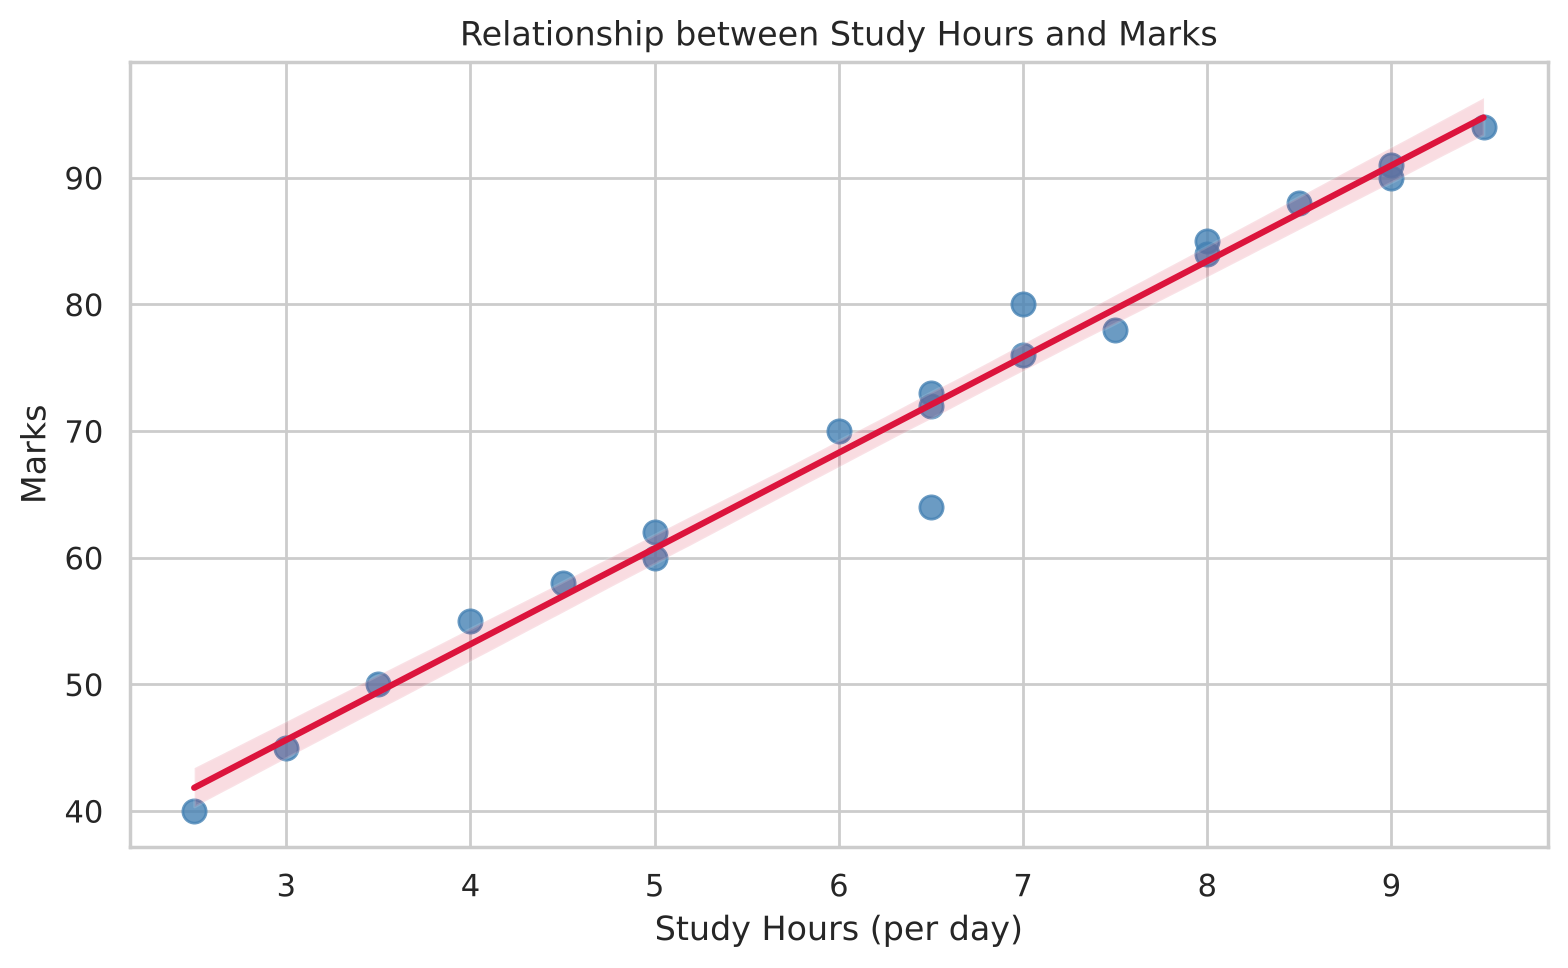

Correlation (Study Hours vs Marks): 0.989


In [11]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Study Hours", y="Marks", color="steelblue",
            scatter_kws={"s": 70}, line_kws={"color": "crimson"})
plt.title("Relationship between Study Hours and Marks")
plt.xlabel("Study Hours (per day)")
plt.ylabel("Marks")
plt.tight_layout()
plt.savefig("study_hours_vs_marks.png", dpi=150)
plt.show()

print("Correlation (Study Hours vs Marks): %.3f" % df["Study Hours"].corr(df["Marks"]))

## Question 7: Histogram of student marks

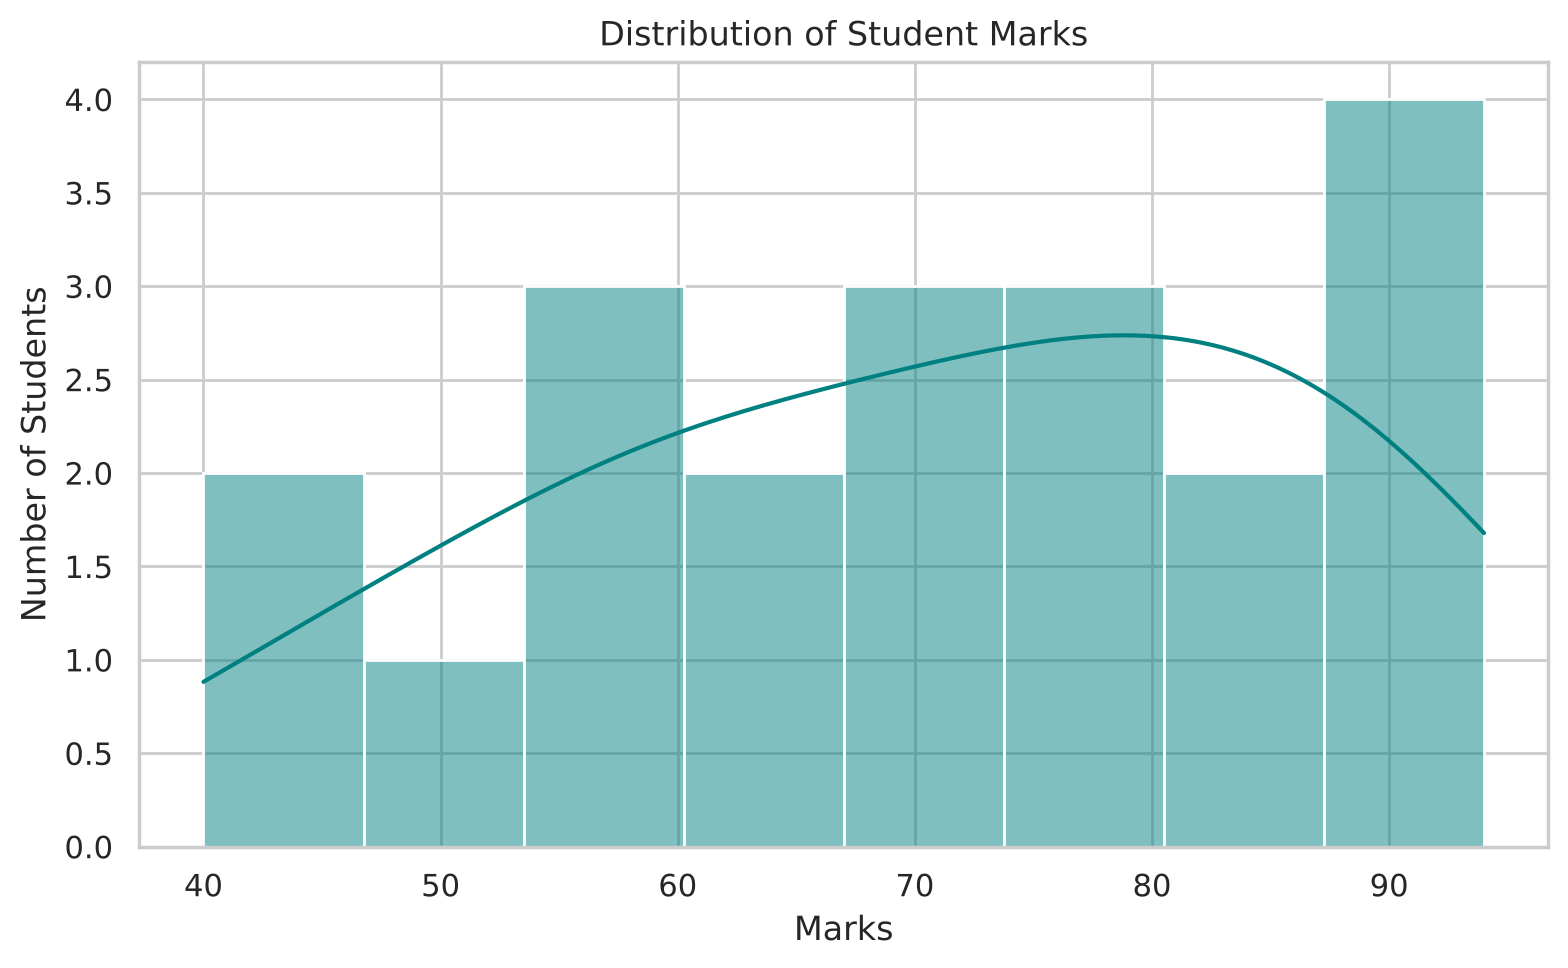

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Marks", bins=8, kde=True, color="teal")
plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig("marks_histogram.png", dpi=150)
plt.show()

## Conclusion

- Marks statistics were calculated with NumPy.
- Missing values were filled with the column median and the duplicate record was removed with Pandas.
- Seaborn shows a strong positive relationship between study hours and marks.
- The cleaned dataset is saved as `students_cleaned.csv`.